In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer

# Load the Encoded Data
print("Loading model data...")
df = pd.read_csv('../data/processed/engineered_dataset.csv')

# Separating the Target Variable (y) and Features (X)
X = df.drop(columns=['Readmission_Risk'])
y = df['Readmission_Risk']

# Splitting the Data into Train and Test Sets
# Splitting as 80% Train, 20% Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training Data Distribution Before SMOTE:\n{y_train.value_counts()}")

# ---------------- NEWLY ADDED PART ----------------
# Imputing Missing Data (NaN)
print("\nImputing missing data (NaN) with median values...")
imputer = SimpleImputer(strategy='median')

# Fitting and transforming only on the training data
X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)

# Transforming the test data using the same rule
X_test_imputed = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)
# -----------------------------------------------------

# Oversampling the Minority Class with SMOTE
print("Running the SMOTE algorithm...")
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_imputed, y_train)

# Saving the Prepared Data for Future Use
X_train_smote.to_csv('../data/processed/X_train.csv', index=False)
y_train_smote.to_csv('../data/processed/y_train.csv', index=False)
X_test_imputed.to_csv('../data/processed/X_test.csv', index=False)
y_test.to_csv('../data/processed/y_test.csv', index=False)

print("-" * 50)
print("Data splitting, Missing Data Imputation, and SMOTE process successfully completed!")
print("New Training Data Distribution After SMOTE:")
print(y_train_smote.value_counts())

Loading model data...
Training Data Distribution Before SMOTE:
Readmission_Risk
0    72326
1     9086
Name: count, dtype: int64

Imputing missing data (NaN) with median values...
Running the SMOTE algorithm...
--------------------------------------------------
Data splitting, Missing Data Imputation, and SMOTE process successfully completed!
New Training Data Distribution After SMOTE:
Readmission_Risk
0    72326
1    72326
Name: count, dtype: int64


DATA STANDARDIZATION AND VISUALIZATION STARTING ---


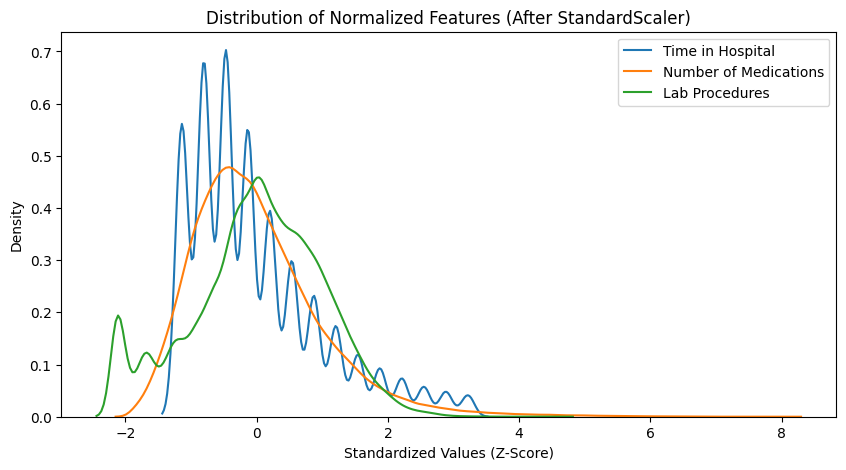

Data successfully standardized, saved, and Figure 5 plotted!
Scaler object (Z-Score) successfully saved!


In [2]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

print("DATA STANDARDIZATION AND VISUALIZATION STARTING ---")

# Reading the data
df_scale = pd.read_csv('../data/processed/custom_readmission_dataset.csv')

# Selecting numerical columns (excluding the target column)
target_col = 'readmitted_risk' if 'readmitted_risk' in df_scale.columns else 'readmitted'
numeric_cols = df_scale.select_dtypes(include=['int64', 'float64']).columns
numeric_cols = numeric_cols.drop(target_col, errors='ignore')

# Applying StandardScaler
scaler = StandardScaler()
df_scale[numeric_cols] = scaler.fit_transform(df_scale[numeric_cols])

# Plotting an example (To prove normalization)
plt.figure(figsize=(10, 5))
sns.kdeplot(data=df_scale, x='time_in_hospital', label='Time in Hospital')
sns.kdeplot(data=df_scale, x='num_medications', label='Number of Medications')
sns.kdeplot(data=df_scale, x='num_lab_procedures', label='Lab Procedures')
plt.title("Distribution of Normalized Features (After StandardScaler)")
plt.xlabel("Standardized Values (Z-Score)")
plt.ylabel("Density")
plt.legend()
plt.show()

# Saving the scaled data for subsequent stages
df_scale.to_csv('../data/processed/scaled_readmission_dataset.csv', index=False)

print("Data successfully standardized, saved, and Figure 5 plotted!")

joblib.dump(scaler, '../data/processed/scaler.pkl')
print("Scaler object (Z-Score) successfully saved!")